# 02 Model comparison and annotation agreement

Needs `data/labelled/labelled_pairs.csv` (your reviewed labelling sheet) and `data/raw/Hotel_Reviews.csv`.
**Colab:** use a GPU runtime if you can (Runtime > Change runtime type); the transformers also run on CPU, just slower. After changing anything in `src/`, use Runtime > Restart session.

In [1]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    import os
    os.chdir('/content/drive/MyDrive/hotel-review-aspect-sentiment/notebooks')
except ImportError:
    pass

In [2]:
# Colab usually has transformers/torch already. Uncomment if an import below fails:
# !pip install -q transformers sentencepiece
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt

from src.pipeline import load_reviews, split_sentences, add_difficulty_flags
from src import models as M
from src import evaluate as E

ROOT = Path.cwd().parent
DATA_PATH = ROOT / "data" / "raw" / "Hotel_Reviews.csv"
LABELS_PATH = ROOT / "data" / "labelled" / "labelled_pairs.csv"
OUT = ROOT / "outputs"; OUT.mkdir(exist_ok=True)
SEED, N_REVIEWS = 42, 20000      # must match notebook 01

## 1. Load your labels and check them
Stops with a clear message if any row has a blank or misspelt `gold_sentiment` / `difficulty`.

In [3]:
lab = E.load_labelled(LABELS_PATH)
print(len(lab), "labelled pairs")
print(lab["gold_sentiment"].value_counts())
print(lab["difficulty"].value_counts())

201 labelled pairs
gold_sentiment
positive          94
negative          81
neutral           18
not_applicable     8
Name: count, dtype: int64
difficulty
multi_aspect    70
plain           59
contrast        37
negation        35
Name: count, dtype: int64


## 2. Annotation agreement: your labels vs the AI pre-labels
The AI labels were a starting point that you reviewed and corrected, so this is **not** independent inter-annotator agreement. It shows how often the AI draft needed fixing, and where. Cohen's kappa corrects raw agreement for chance. Report both, and say plainly in the report that the labels are AI-assisted and human-verified.

In [4]:
ag = E.annotation_agreement(lab)
for k, v in ag.items():
    if k not in ("confusion", "changed_rows"):
        print(f"{k:24s}", round(v, 3) if isinstance(v, float) else v)
ag["confusion"]

n                        201
sentiment_agreement      0.995
sentiment_kappa          0.992
sentiment_changed        1
not_applicable_gold      8
not_applicable_ai        9
difficulty_agreement     1.0
difficulty_kappa         1.0
difficulty_changed       0


,ai:negative,ai:neutral,ai:positive,ai:not_applicable
human:negative,80,0,0,1
human:neutral,0,18,0,0
human:positive,0,0,94,0
human:not_applicable,0,0,0,8


In [5]:
# Every row where you disagreed with the AI draft (good material for the report's annotation section).
ag["changed_rows"].to_csv(OUT / "annotation_changes.csv", index=False)
ag["changed_rows"]

,review_id,sent_id,aspect,sentence,gold_sentiment,ai_sentiment
177,11506,1,location,Room too close to breakfast room door do could...,negative,not_applicable


## 3. Rebuild the sentences and the weak-label training data
Same sample as notebook 01 (same seed). Training data for the TF-IDF model = all comments of at least 3 words whose **review** is not among the labelled ones, so nothing you hand-labelled leaks into training.

In [6]:
df = load_reviews(DATA_PATH, n_sample=N_REVIEWS, seed=SEED)
flagged = add_difficulty_flags(split_sentences(df))

key = lambda r, s: (r, s)
field_by_key = {(r, s): f for r, s, f in zip(flagged["review_id"], flagged["sent_id"], flagged["field"])}
missing = [k for k in zip(lab["review_id"], lab["sent_id"]) if k not in field_by_key]
assert not missing, f"{len(missing)} labelled sentences not found: N_REVIEWS/SEED differ from notebook 01?"

train = flagged[(flagged["n_words"] >= 3) & (~flagged["review_id"].isin(lab["review_id"]))]
print(len(train), "weak-labelled training comments")

29735 weak-labelled training comments


## 4. Fit and run the models
Only rows with a real sentiment are scored (`not_applicable` rows are keyword false alarms, so they are excluded from model scoring and reported separately).

In [7]:
ev = E.evaluable(lab)
print(len(ev), "rows scored;", len(lab) - len(ev), "not_applicable rows excluded")

preds = {}
majority = M.MajorityModel().fit(train["field"])
preds[majority.name] = majority.predict(ev)
preds[M.BoxLabelModel(field_by_key).name] = M.BoxLabelModel(field_by_key).predict(ev)
tfidf = M.TfidfLRModel(SEED).fit(train["sentence"], train["field"])
preds[tfidf.name] = tfidf.predict(ev)
{k: pd.Series(v).value_counts().to_dict() for k, v in preds.items()}

193 rows scored; 8 not_applicable rows excluded


{'Majority class': {'positive': 193},
 'Box label (weak reference)': {'positive': 97, 'negative': 96},
 'TF-IDF + LogReg (weak labels)': {np.str_('negative'): 100,
  np.str_('positive'): 93}}

In [8]:
# Pretrained transformers (download on first run). Wrapped so one failure does not stop the notebook.
for cls in (M.HFSentimentModel, M.HFAbsaModel):
    try:
        m = cls(device=0 if __import__("torch").cuda.is_available() else -1)
        preds[m.name] = m.predict(ev)
        print("ok:", m.name)
    except Exception as e:
        print("FAILED:", cls.__name__, "->", type(e).__name__, str(e)[:200])

ok: RoBERTa sentiment (pretrained)


ok: DeBERTa ABSA (pretrained)


## 5. Results by difficulty group
The central question: do the models cope with negation, contrast and several aspects in one comment? Only the ABSA model is told *which aspect* to judge, so on multi-aspect and contrast rows it has a real advantage on paper. Check whether the numbers show it.

In [9]:
scores = E.score_models(ev, preds)
table = scores.pivot(index="model", columns="subset", values="macro_f1")[["all"] + [d for d in E.DIFFICULTIES if d in set(scores["subset"])]].round(3)
scores.to_csv(OUT / "model_scores.csv", index=False)
table

subset,all,negation,contrast,multi_aspect,plain
model,,,,,
Box label (weak reference),0.604,0.484,0.401,0.633,0.660
DeBERTa ABSA (pretrained),0.627,0.480,0.525,0.630,0.599
Majority class,0.218,0.019,0.201,0.282,0.228
RoBERTa sentiment (pretrained),0.575,0.436,0.358,0.657,0.492
TF-IDF + LogReg (weak labels),0.594,0.456,0.376,0.645,0.635


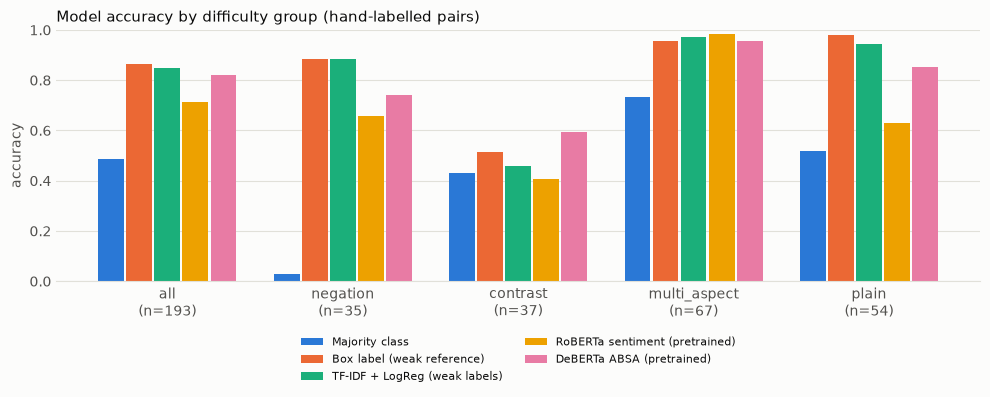

In [10]:
fig = E.plot_by_difficulty(scores, "accuracy", OUT / "accuracy_by_difficulty.png")
plt.show()

In [11]:
# With about 200 rows (and fewer per group) differences are noisy: 95% bootstrap intervals for overall accuracy.
ci = {m: E.bootstrap_ci(ev, p, "accuracy", seed=SEED) for m, p in preds.items()}
pd.DataFrame(ci, index=["low", "high"]).T.round(3)

,low,high
Majority class,0.415,0.554
Box label (weak reference),0.819,0.912
TF-IDF + LogReg (weak labels),0.798,0.896
RoBERTa sentiment (pretrained),0.648,0.772
DeBERTa ABSA (pretrained),0.756,0.865


## 6. Error analysis
Read these. The report's discussion should quote a few real failures per hard case and explain why they happen.

In [12]:
errors = pd.concat([E.error_table(ev, p, m) for m, p in preds.items()
                    if m not in ("Majority class", "Box label (weak reference)")])
errors.to_csv(OUT / "model_errors.csv", index=False)
pd.set_option("display.max_colwidth", 140)
errors.groupby(["model", "difficulty"]).size().unstack(fill_value=0)

difficulty,contrast,multi_aspect,negation,plain
model,,,,
DeBERTa ABSA (pretrained),15,3,9,8
RoBERTa sentiment (pretrained),22,1,12,20
TF-IDF + LogReg (weak labels),20,2,4,3


In [13]:
# Rows where the aspect-aware model is right and the aspect-blind RoBERTa is wrong (and the reverse).
a, b = "DeBERTa ABSA (pretrained)", "RoBERTa sentiment (pretrained)"
if a in preds and b in preds:
    y = ev["gold_sentiment"]
    pa, pb = pd.Series(preds[a]), pd.Series(preds[b])
    print("ABSA right, RoBERTa wrong:", int(((pa == y) & (pb != y)).sum()),
          "| RoBERTa right, ABSA wrong:", int(((pb == y) & (pa != y)).sum()))
    ev.assign(absa=pa, roberta=pb)[(pa == y) & (pb != y)][["difficulty", "aspect", "sentence", "gold_sentiment", "absa", "roberta"]].head(15)

ABSA right, RoBERTa wrong: 30 | RoBERTa right, ABSA wrong: 10


## 7. Optional: an LLM prompt
Supply any function that sends a prompt to an LLM and returns its text. **Circularity caveat:** the pre-labels came from an LLM, so an LLM scoring well here is partly agreeing with its own family's draft, even after your corrections. Say so in the report if you use this.

In [14]:
# Example (needs your own API key; leave commented if you skip this):
# ask = lambda p: your_llm_call(p)  # any function that takes a prompt and returns text
# llm = M.LLMPromptModel(ask, "LLM prompt"); preds[llm.name] = llm.predict(ev)

## Next steps
1. Put the table, chart and 3 to 5 real error examples in report section 3 (Results and discussion).
2. Mention the annotation process and its limits (AI-assisted, one human verifier, about 200 rows) in section 2.
3. Build the Gradio demo around the best model.